## Importing Lararise

In [28]:
from itertools import groupby

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.core.pylabtools import figsize
from debugpy.launcher import output
from fontTools.diff import color
from numpy.ma.extras import average

Matplotlib is building the font cache; this may take a moment.


## Loding Data ##

In [5]:
df=pd.read_csv(r"F:\Projects om kadam\archive\healthcare_dataset.csv")
df

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,Bobby JacksOn,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal
1,LesLie TErRy,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive
2,DaNnY sMitH,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal
3,andrEw waTtS,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal
4,adrIENNE bEll,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
55495,eLIZABeTH jaCkSOn,42,Female,O+,Asthma,2020-08-16,Joshua Jarvis,Jones-Thompson,Blue Cross,2650.714952,417,Elective,2020-09-15,Penicillin,Abnormal
55496,KYle pEREz,61,Female,AB-,Obesity,2020-01-23,Taylor Sullivan,Tucker-Moyer,Cigna,31457.797307,316,Elective,2020-02-01,Aspirin,Normal
55497,HEATher WaNG,38,Female,B+,Hypertension,2020-07-13,Joe Jacobs DVM,"and Mahoney Johnson Vasquez,",UnitedHealthcare,27620.764717,347,Urgent,2020-08-10,Ibuprofen,Abnormal
55498,JENniFER JOneS,43,Male,O-,Arthritis,2019-05-25,Kimberly Curry,"Jackson Todd and Castro,",Medicare,32451.092358,321,Elective,2019-05-31,Ibuprofen,Abnormal


## Inpact the Data

In [6]:
df.head()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,Bobby JacksOn,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal
1,LesLie TErRy,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive
2,DaNnY sMitH,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal
3,andrEw waTtS,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal
4,adrIENNE bEll,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal


In [7]:
df.tail()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
55495,eLIZABeTH jaCkSOn,42,Female,O+,Asthma,2020-08-16,Joshua Jarvis,Jones-Thompson,Blue Cross,2650.714952,417,Elective,2020-09-15,Penicillin,Abnormal
55496,KYle pEREz,61,Female,AB-,Obesity,2020-01-23,Taylor Sullivan,Tucker-Moyer,Cigna,31457.797307,316,Elective,2020-02-01,Aspirin,Normal
55497,HEATher WaNG,38,Female,B+,Hypertension,2020-07-13,Joe Jacobs DVM,"and Mahoney Johnson Vasquez,",UnitedHealthcare,27620.764717,347,Urgent,2020-08-10,Ibuprofen,Abnormal
55498,JENniFER JOneS,43,Male,O-,Arthritis,2019-05-25,Kimberly Curry,"Jackson Todd and Castro,",Medicare,32451.092358,321,Elective,2019-05-31,Ibuprofen,Abnormal
55499,jAMES GARCiA,53,Female,O+,Arthritis,2024-04-02,Dennis Warren,Henry Sons and,Aetna,4010.134172,448,Urgent,2024-04-29,Ibuprofen,Abnormal


In [8]:
df.shape

(55500, 15)

In [9]:
df.columns

Index(['Name', 'Age', 'Gender', 'Blood Type', 'Medical Condition',
       'Date of Admission', 'Doctor', 'Hospital', 'Insurance Provider',
       'Billing Amount', 'Room Number', 'Admission Type', 'Discharge Date',
       'Medication', 'Test Results'],
      dtype='str')

In [10]:
df.dtypes

Name                      str
Age                     int64
Gender                    str
Blood Type                str
Medical Condition         str
Date of Admission         str
Doctor                    str
Hospital                  str
Insurance Provider        str
Billing Amount        float64
Room Number             int64
Admission Type            str
Discharge Date            str
Medication                str
Test Results              str
dtype: object

In [11]:
df.isnull().sum()

Name                  0
Age                   0
Gender                0
Blood Type            0
Medical Condition     0
Date of Admission     0
Doctor                0
Hospital              0
Insurance Provider    0
Billing Amount        0
Room Number           0
Admission Type        0
Discharge Date        0
Medication            0
Test Results          0
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(534)

In [13]:
df.describe() # stastics summry of numeric collums

,Age,Billing Amount,Room Number
count,55500.000000,55500.000000,55500.000000
mean,51.539459,25539.316097,301.134829
std,19.602454,14211.454431,115.243069
min,13.000000,-2008.492140,101.000000
25%,35.000000,13241.224652,202.000000
50%,52.000000,25538.069376,302.000000
75%,68.000000,37820.508436,401.000000
max,89.000000,52764.276736,500.000000


## Data Cleaning

## Removing Duplicates

In [14]:
df= df.drop_duplicates()

In [15]:
df.duplicated().sum()

np.int64(0)

## Cleaning Names Collumns

In [16]:
df['Name']= df['Name'].str.strip().str.title()

In [17]:
df.head

<bound method NDFrame.head of                     Name  Age  Gender Blood Type Medical Condition  \
0          Bobby Jackson   30    Male         B-            Cancer   
1           Leslie Terry   62    Male         A+           Obesity   
2            Danny Smith   76  Female         A-           Obesity   
3           Andrew Watts   28  Female         O+          Diabetes   
4          Adrienne Bell   43  Female        AB+            Cancer   
...                  ...  ...     ...        ...               ...   
55495  Elizabeth Jackson   42  Female         O+            Asthma   
55496         Kyle Perez   61  Female        AB-           Obesity   
55497       Heather Wang   38  Female         B+      Hypertension   
55498     Jennifer Jones   43    Male         O-         Arthritis   
55499       James Garcia   53  Female         O+         Arthritis   

      Date of Admission            Doctor                      Hospital  \
0            2024-01-31     Matthew Smith             

## 3. Fix Negitive Billing Amounts

In [18]:
df.loc[df['Billing Amount']<0,'Billing Amount'] = df['Billing Amount'].mean()

In [19]:
df.describe()

,Age,Billing Amount,Room Number
count,54966.000000,54966.000000,54966.000000
mean,51.535185,25594.536582,301.124404
std,19.605661,14162.191537,115.223143
min,13.000000,9.238787,101.000000
25%,35.000000,13326.001350,202.000000
50%,52.000000,25544.306284,302.000000
75%,68.000000,37819.858159,401.000000
max,89.000000,52764.276736,500.000000


In [20]:
df.head()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,Bobby Jackson,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal
1,Leslie Terry,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive
2,Danny Smith,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal
3,Andrew Watts,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal
4,Adrienne Bell,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal


In [21]:
df['Date of Admission']=pd.to_datetime(df['Date of Admission'])

In [22]:
df['Discharge Date']=pd.to_datetime(df['Discharge Date'])

In [23]:
df.dtypes

Name                             str
Age                            int64
Gender                           str
Blood Type                       str
Medical Condition                str
Date of Admission     datetime64[us]
Doctor                           str
Hospital                         str
Insurance Provider               str
Billing Amount               float64
Room Number                    int64
Admission Type                   str
Discharge Date        datetime64[us]
Medication                       str
Test Results                     str
dtype: object

In [24]:
df['Lenth_of_stay']=(df['Discharge Date']-df['Date of Admission']).dt.days

In [25]:
df.head()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results,Lenth_of_stay
0,Bobby Jackson,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal,2
1,Leslie Terry,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive,6
2,Danny Smith,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal,15
3,Andrew Watts,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal,30
4,Adrienne Bell,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal,20


## final clening check

In [26]:
df.isnull().sum()

Name                  0
Age                   0
Gender                0
Blood Type            0
Medical Condition     0
Date of Admission     0
Doctor                0
Hospital              0
Insurance Provider    0
Billing Amount        0
Room Number           0
Admission Type        0
Discharge Date        0
Medication            0
Test Results          0
Lenth_of_stay         0
dtype: int64

In [27]:
df.shape

(54966, 16)

## Data Analysis And Data Visualization

## 1.   Which medical condation affects the most patient across the network

In [29]:
condition_count=df['Medical Condition'].value_counts()
condition_count

Medical Condition
Arthritis       9218
Diabetes        9216
Hypertension    9151
Obesity         9146
Cancer          9140
Asthma          9095
Name: count, dtype: int64

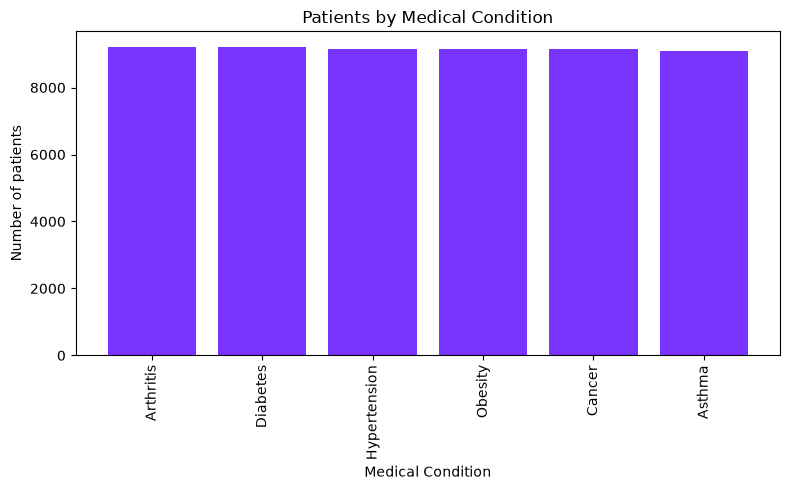

In [32]:
plt.figure(figsize=(8,5))
plt.bar(condition_count.index,condition_count.values,color='#7833FE')
plt.title('Patients by Medical Condition')
plt.xlabel('Medical Condition')
plt.ylabel('Number of patients')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


In [ ]:
## 2. How is Patient age distributed across the network?

In [34]:
average_age=df['Age'].mean()
average_age

np.float64(51.53518538733035)

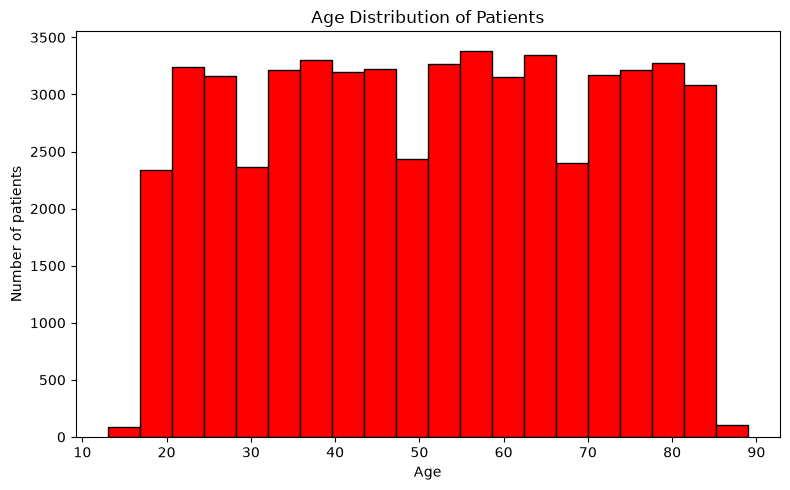

In [35]:
plt.figure(figsize=(8,5))
plt.hist(df['Age'],bins=20,color='Red',edgecolor='black')
plt.title('Age Distribution of Patients')
plt.xlabel('Age')
plt.ylabel('Number of patients')
plt.tight_layout()
plt.show()

In [ ]:
## 3. How has average treatment cost changed over time?

In [37]:
average_cost=df['Billing Amount'].mean()
average_cost

np.float64(25594.536582219524)

In [39]:
df['Admission_Month']=df['Date of Admission'].dt.to_period('M')
monthly_avg_cost=df.groupby('Admission_Month')['Billing Amount'].mean()
monthly_avg_cost


Admission_Month
2019-05    25897.449655
2019-06    26324.004064
2019-07    25928.602371
2019-08    25457.102225
2019-09    24915.548929
               ...     
2024-01    25836.695757
2024-02    25703.588425
2024-03    25310.583403
2024-04    24930.033214
2024-05    25464.902913
Freq: M, Name: Billing Amount, Length: 61, dtype: float64

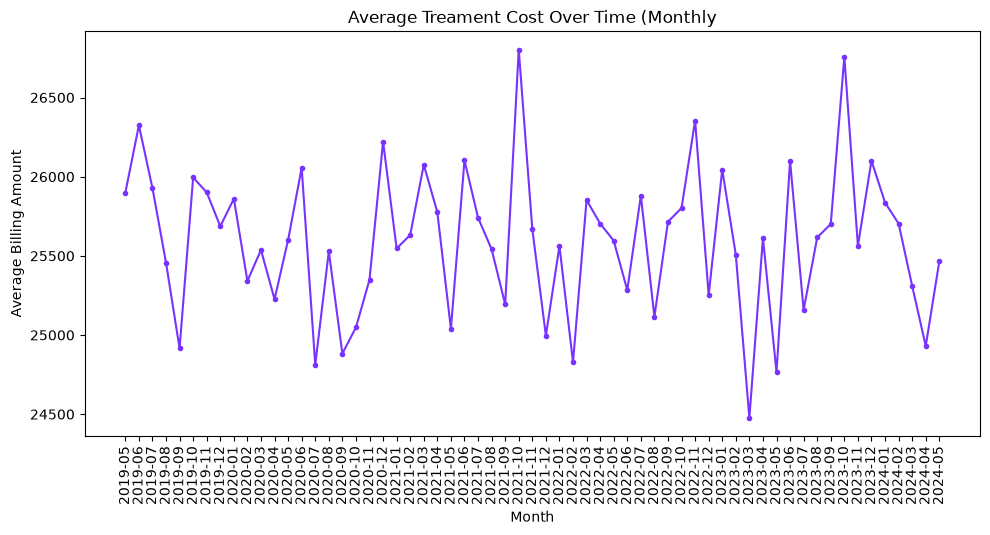

In [41]:
plt.figure(figsize=(10,5))
plt.plot(monthly_avg_cost.index.astype(str),monthly_avg_cost.values,color='#7833FE',marker='o',markersize=3)
plt.title("Average Treament Cost Over Time (Monthly")
plt.xlabel('Month')
plt.ylabel('Average Billing Amount')
plt.tight_layout()
plt.xticks(rotation=90)
plt.show()

In [ ]:
## 4. Is there a relationship between paient Age and Treatment cost ?

In [42]:
senior_avg_cost=df.loc[df['Age']>=60,'Billing Amount'].mean()
senior_avg_cost

np.float64(25563.58776383007)

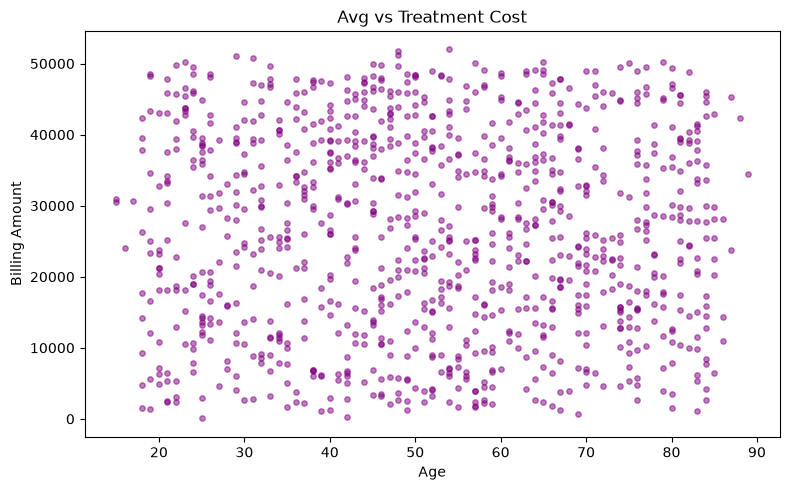

In [49]:
sample_df=df.sample(1000,random_state=1)
plt.figure(figsize=(8,5))
plt.scatter(sample_df['Age'],sample_df['Billing Amount'],color='purple',alpha=0.5,s=15)
plt.title('Avg vs Treatment Cost')
plt.xlabel('Age')
plt.ylabel('Billing Amount')
plt.tight_layout()
plt.show()



In [ ]:
## 5. Which insurance provider cover the most poients ?

In [51]:
insurance_count=df['Insurance Provider'].value_counts()
insurance_count

Insurance Provider
Cigna               11139
Medicare            11039
UnitedHealthcare    11014
Blue Cross          10952
Aetna               10822
Name: count, dtype: int64

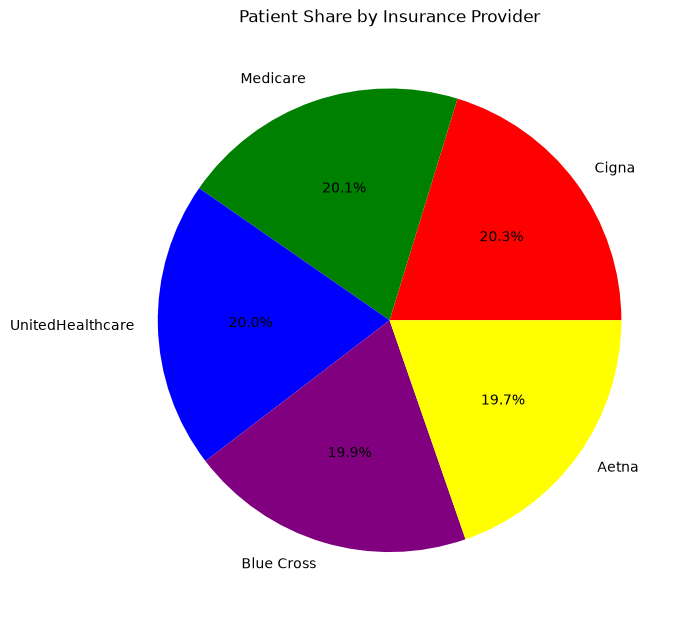

In [58]:
plt.figure(figsize=(7,7))
plt.pie(insurance_count.values,labels=insurance_count.index,autopct='%1.1f%%',colors=['Red','Green','Blue','Purple','Yellow'])
plt.title('Patient Share by Insurance Provider')
plt.tight_layout()
plt.show()

In [60]:
 df.head()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results,Lenth_of_stay,Admission_Month
0,Bobby Jackson,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal,2,2024-01
1,Leslie Terry,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive,6,2019-08
2,Danny Smith,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal,15,2022-09
3,Andrew Watts,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal,30,2020-11
4,Adrienne Bell,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal,20,2022-09


In [ ]:
# Ad HOC Questions


In [ ]:
# AD-HOC Question 1. - Emergency Deparment capacity Planing

In [ ]:
## "Business scenario 1:The Hospital managment is planning staffing for emergency cases. They want know how many emergency admission occures in eac month" ##

In [61]:
df.dtypes

Name                             str
Age                            int64
Gender                           str
Blood Type                       str
Medical Condition                str
Date of Admission     datetime64[us]
Doctor                           str
Hospital                         str
Insurance Provider               str
Billing Amount               float64
Room Number                    int64
Admission Type                   str
Discharge Date        datetime64[us]
Medication                       str
Test Results                     str
Lenth_of_stay                  int64
Admission_Month            period[M]
dtype: object

In [66]:
emergency_month=(df.loc[df['Admission Type']=='Emergency'].groupby(df['Date of Admission'].dt.month).size())
emergency_month

Date of Admission
1     1547
2     1452
3     1528
4     1473
5     1533
6     1483
7     1573
8     1533
9     1500
10    1490
11    1462
12    1528
dtype: int64

In [ ]:
# AD-HOC Question 2. - Indentify High-cost Patient Group

In [ ]:
## "Business scenario : Hospital Finance team want to Identify patients who have Unusually High illing Amounts so they can review those cases

In [71]:
high_cost_patients=df.loc[df['Billing Amount']>df['Billing Amount'].quantile(0.90)]
high_cost_patients

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results,Lenth_of_stay,Admission_Month
5,Emily Johnson,36,Male,A+,Asthma,2023-12-20,Taylor Newton,Nunez-Humphrey,UnitedHealthcare,48145.110951,389,Urgent,2023-12-24,Ibuprofen,Normal,4,2023-12
7,Christina Martinez,20,Female,A+,Cancer,2021-12-28,Suzanne Thomas,"Powell Robinson and Valdez,",Cigna,45820.462722,277,Emergency,2022-01-07,Paracetamol,Inconclusive,10,2021-12
8,Jasmine Aguilar,82,Male,AB+,Asthma,2020-07-01,Daniel Ferguson,Sons Rich and,Cigna,50119.222792,316,Elective,2020-07-14,Aspirin,Abnormal,13,2020-07
30,Thomas Martinez,34,Male,B-,Asthma,2019-08-18,Jacob Huynh,Hart Ltd,Cigna,47909.128810,371,Urgent,2019-09-01,Ibuprofen,Inconclusive,14,2019-08
35,David Anderson,25,Female,AB+,Asthma,2021-01-07,Emma Allison,Sons and Cox,Medicare,45453.418546,228,Elective,2021-01-26,Lipitor,Abnormal,19,2021-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
55446,Richard Moore,63,Female,B+,Hypertension,2021-11-17,Dr. Jacob Aguilar,Blevins Group,Aetna,47649.696638,304,Emergency,2021-12-09,Penicillin,Abnormal,22,2021-11
55465,Amanda Stevens,71,Female,O-,Asthma,2019-06-11,Jessica Ramirez,Sims-Henderson,Cigna,45597.476264,164,Urgent,2019-06-22,Ibuprofen,Inconclusive,11,2019-06
55467,Sandra Chen,62,Female,B+,Asthma,2022-06-03,Morgan Hess,Park Ltd,Aetna,48563.608920,269,Emergency,2022-06-06,Lipitor,Abnormal,3,2022-06
55470,Taylor Best,60,Male,A-,Asthma,2020-10-14,Tracy Nichols,"Hopkins and Neal Logan,",Cigna,48664.879041,187,Emergency,2020-10-21,Penicillin,Normal,7,2020-10


In [ ]:
# AD-HOC Question 3. Flagging Emergency cases with Abnormal Results for Review

In [ ]:
## "Business scenario 1. "Hospital management want to indentify emergency petient whose test results are Abnormal so cases can be prioritized for review"

In [72]:
priority_cases=df.loc[(df['Admission Type']=='Emergency') & (df['Test Results']=='Abnormal')]
priority_cases

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results,Lenth_of_stay,Admission_Month
12,Connor Hansen,75,Female,A+,Diabetes,2019-12-12,Kenneth Fletcher,"Powers Miller, and Flores",Cigna,43282.283358,134,Emergency,2019-12-28,Penicillin,Abnormal,16,2019-12
27,Mr. Kenneth Moore,34,Female,A+,Diabetes,2022-06-21,James Ellis,Serrano-Dixon,UnitedHealthcare,18834.801341,157,Emergency,2022-06-30,Lipitor,Abnormal,9,2022-06
38,Nicole Lucero,70,Female,O-,Diabetes,2022-03-12,Christine Johnson,"and Garcia Morris Cunningham,",Cigna,48290.693407,113,Emergency,2022-03-29,Lipitor,Abnormal,17,2022-03
51,Stephanie Kent,42,Female,A-,Cancer,2019-06-15,Mary Moss,Beck-Galloway,Aetna,14681.016360,234,Emergency,2019-07-05,Ibuprofen,Abnormal,20,2019-06
64,Nancy Glover,58,Male,A-,Hypertension,2020-05-08,Jennifer Larson,"Khan, and Rodriguez Fischer",Medicare,19183.168885,378,Emergency,2020-06-01,Aspirin,Abnormal,24,2020-05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
55471,Ian Murphy,73,Female,B+,Hypertension,2023-05-03,Leslie Guerra,Lozano Ltd,Aetna,28397.377193,348,Emergency,2023-05-06,Lipitor,Abnormal,3,2023-05
55480,Lauren Mills,33,Female,B-,Diabetes,2020-09-30,Mr. David Murray MD,"Riggs, King and Walls",Cigna,22375.523434,323,Emergency,2020-10-26,Aspirin,Abnormal,26,2020-09
55488,Brittney York,43,Female,B-,Obesity,2024-02-02,Richard Matthews,Malone Ltd,Blue Cross,8128.932064,469,Emergency,2024-02-04,Aspirin,Abnormal,2,2024-02
55490,Stephanie Oliver,82,Male,B-,Cancer,2022-01-10,Gary Leblanc,Group Lee,Cigna,17350.543524,381,Emergency,2022-01-21,Penicillin,Abnormal,11,2022-01
